# Phase 2C | Pulse-aware optogenetic neural-response prediction

**DANDI 000568 | Real NWB recordings | Two time horizons | GRU/TCN/XGBoost | Matched optical ablations | Animal-independence audit**

**Research question:** Does adding *correctly timed, site-resolved pulse-train information* improve held-out-session prediction of mouse hippocampal neural firing rate over neural history alone?

**Scope and limitations**
- These are recordings from **one mouse**, with Session 9 and Session 12 tested in both directions. A recording session is **not an independent animal**.
- The model receives the **observed future optical schedule**. This is offline conditional forecasting, **not** a counterfactual simulator, validated closed-loop control, or proof of a causal stimulation effect.
- Raw optical `data` codes differ dramatically between the two sessions; their physical units/calibration are not established. **Do not interpret them as watts** or enter them into the predictive model as comparable intensity levels.
- No clinical epilepsy labels are used. Do not report seizure classification, therapy, or human generalization.
- All plotted outputs are calculated from actual Kaggle-run NWB data, not illustrative figures.

**First run:** Keep `QUICK_MODE=True` to verify every step. After inspecting results, set it to `False` only if additional training is warranted.

## 1 | Environment and reproducible settings

CPU works; Kaggle T4 GPU may train faster. Internet is required to download **two approximately 29 MB and 44 MB small NWB files**. No Kaggle Input is needed. The notebook will refuse large raw recordings.

In [1]:
import sys, subprocess, importlib.util
for package,module in [('numpy','numpy'),('pandas','pandas'),('requests','requests'),
                       ('h5py','h5py'),('matplotlib','matplotlib'),('scipy','scipy'),
                       ('scikit-learn','sklearn'),('torch','torch'),('xgboost','xgboost')]:
    if importlib.util.find_spec(module) is None:
        subprocess.check_call([sys.executable,'-m','pip','install','-q',package])

from pathlib import Path
from datetime import datetime, timezone
from scipy.stats import spearmanr
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor
from torch import nn
from torch.utils.data import TensorDataset,DataLoader
import requests, h5py, numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, zipfile, json, copy, random, re, warnings

SEED=42
QUICK_MODE=True
BIN_SEC=0.010     # 10 ms: finer than the approximately 19-ms observed pulses
HISTORY_BINS=50   # 500 ms of neural/optical history
HORIZONS={'early_0_50ms':(0,5), 'delayed_50_150ms':(5,15)}
CAPS={'train':4500,'val':900,'test':1800} if QUICK_MODE else {'train':14000,'val':2800,'test':6000}
EPOCHS=7 if QUICK_MODE else 18
REPEATS=[42] if QUICK_MODE else [42,73,101]
BATCH_SIZE=256
DANDISET='000568'; VERSION='0.230705.1633'
BASE='https://api.dandiarchive.org'
ROOT=Path('/kaggle/working') if Path('/kaggle/working').exists() else Path('/mnt/data')
OUT=ROOT/'phase2c_outputs'; CACHE=ROOT/'phase2c_nwb_cache'
OUT.mkdir(exist_ok=True,parents=True); CACHE.mkdir(exist_ok=True,parents=True)
DEVICE=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
np.random.seed(SEED); random.seed(SEED); torch.manual_seed(SEED)
torch.set_num_threads(2)
print('Device:',DEVICE,'QUICK_MODE:',QUICK_MODE,'EPOCHS:',EPOCHS)
print('CAPS:',CAPS,'REPEATS:',REPEATS,'OUTPUT:',OUT)

Device: cuda QUICK_MODE: True EPOCHS: 7
CAPS: {'train': 4500, 'val': 900, 'test': 1800} REPEATS: [42] OUTPUT: /kaggle/working/phase2c_outputs


## 2 | Public manifest audit: what constitutes an independent animal?

The manifest distinguishes **raw files, no-raw-data copies, sessions and subjects**. Two copies of the same recording are **not two experiments**. This audit counts independent animals with filename-marked `+ogen` NWB files and writes a complete inventory.

In [2]:
def api_json(url):
    r=requests.get(url,timeout=(20,70),headers={'Accept':'application/json'})
    r.raise_for_status(); return r.json()

def list_assets(dandiset,version,limit_pages=100):
    url=f'{BASE}/api/dandisets/{dandiset}/versions/{version}/assets/?page_size=100'
    records=[]; pages=0
    while url:
        if pages>=limit_pages:
            raise RuntimeError('Asset enumeration exceeded page cap: refusing an incomplete manifest')
        data=api_json(url)
        records.extend(data['results']); pages+=1
        url=data.get('next')
    return pd.DataFrame([{'asset_id':a['asset_id'],'path':a['path'],
                           'size_bytes':int(a['size'])} for a in records])

manifest=list_assets(DANDISET,VERSION)
manifest['subject']=manifest.path.str.extract(r'(^sub-[^/]+)')[0].fillna('unknown')
manifest['is_nwb']=manifest.path.str.endswith('.nwb')
manifest['has_ogen_marker']=manifest.path.str.contains('+ogen',regex=False)
manifest['no_raw_copy']=manifest.path.str.contains('no-raw-data',regex=False)
manifest['session']=manifest.path.str.extract(r'sess(\d+)')[0]
manifest.to_csv(OUT/'full_asset_manifest.csv',index=False)
summary=(manifest[manifest.is_nwb].groupby('subject',as_index=False)
    .agg(nwb_files=('path','size'),marked_ogen_files=('has_ogen_marker','sum'),
         no_raw_copies=('no_raw_copy','sum')))
summary['explicit_ogen_in_name']=summary.marked_ogen_files>0
summary.to_csv(OUT/'independent_animal_manifest_audit.csv',index=False)
print('Total archived assets:',len(manifest),'NWB files:',int(manifest.is_nwb.sum()))
print(summary.to_string(index=False))
print('NOTE: Filename markers are clues, not verified NWB optical measurements.')
small=manifest[(manifest.is_nwb)&(manifest.has_ogen_marker)&(manifest.no_raw_copy)&
               (manifest.size_bytes<70_000_000)].sort_values('size_bytes').copy()
print('Small +ogen candidates:',len(small))
print(small[['path','size_bytes']].to_string(index=False))
if len(small)!=2 or small['subject'].nunique()!=1 or small['session'].nunique()!=2:
    raise RuntimeError('Expected exactly two small +ogen sessions from one mouse; review pinned manifest.')

Total archived assets: 138 NWB files: 56
   subject  nwb_files  marked_ogen_files  no_raw_copies  explicit_ogen_in_name
sub-fCamk1         16                  4              8                   True
sub-fCamk2          8                  0              4                  False
sub-fCamk3         22                  0             11                  False
sub-fCamk5         10                  0              5                  False
NOTE: Filename markers are clues, not verified NWB optical measurements.
Small +ogen candidates: 2
                                                                                      path  size_bytes
sub-fCamk1/sub-fCamk1_ses-fCamk1-200901-sess12-no-raw-data_behavior+ecephys+image+ogen.nwb    28678484
 sub-fCamk1/sub-fCamk1_ses-fCamk1-200827-sess9-no-raw-data_behavior+ecephys+image+ogen.nwb    44441669


## 3 | Download the two small NWB files and audit light encoding

We detect complete positive-to-zero intervals independently for each stimulation site. Pulse values are stored as **uncalibrated raw codes**, excluded from modeling. Existence of overlapping time ranges is necessary for alignment, but does not prove sub-millisecond synchronization.

In [3]:
def download_small_asset(row):
    path=str(row['path']); nbytes=int(row['size_bytes'])
    if not (path.endswith('.nwb') and '+ogen' in path and 'no-raw-data' in path and nbytes<70_000_000):
        raise ValueError('Refusing a potentially large or unexpected download')
    target=CACHE/path.split('/')[-1]
    if target.exists() and target.stat().st_size==nbytes: return target
    temporary=target.with_suffix('.nwb.part')
    with requests.get(f"{BASE}/api/assets/{row['asset_id']}/download/",
                      stream=True,timeout=(30,180)) as response:
        response.raise_for_status()
        with temporary.open('wb') as file:
            for block in response.iter_content(1024*1024):
                if block: file.write(block)
    if temporary.stat().st_size!=nbytes: raise IOError('NWB download size mismatch')
    temporary.replace(target)
    return target

paths={}
for _,row in small.iterrows():
    lab='session_'+str(row['session'])
    paths[lab]=download_small_asset(row)
    print(lab,paths[lab].name,round(paths[lab].stat().st_size/1e6,2),'MB')
assert sorted(paths)==['session_12','session_9']

def decode(x): return x.decode('utf-8','replace') if isinstance(x,bytes) else str(x)

def read_pulse_intervals(hf,session):
    presentation=hf.get('/stimulus/presentation')
    if presentation is None: raise RuntimeError('Missing NWB stimulus/presentation')
    rows=[]; raw_series=[]
    for name,group in presentation.items():
        if not (isinstance(group,h5py.Group) and name.startswith('OptogeneticSeriesSite')):
            continue
        if 'data' not in group or 'timestamps' not in group: continue
        time=np.asarray(group['timestamps'][:],dtype=np.float64)
        value=np.asarray(group['data'][:],dtype=np.float64).reshape(-1)
        if len(time)!=len(value) or len(time)<3 or not np.all(np.diff(time)>=0):
            warnings.warn('Invalid optical time series '+name);continue
        positive=np.isfinite(value)&(value>0)
        begins=np.flatnonzero(positive & ~np.r_[False,positive[:-1]])
        ends=np.flatnonzero(~positive & np.r_[False,positive[:-1]])
        if positive[0]: begins=begins[1:]  # cannot infer a left-censored onset
        j=np.searchsorted(ends,begins,side='right')
        for start,end in zip(begins[j<len(ends)],ends[j[j<len(ends)]]):
            if time[end]<=time[start]:continue
            rows.append({'session':session,'site':name.replace('OptogeneticSeries',''),
                         'onset_sec':float(time[start]),'offset_sec':float(time[end]),
                         'duration_sec':float(time[end]-time[start]),
                         'raw_code':float(value[start]),
                         'reported_unit':decode(group['data'].attrs.get('unit','unknown'))})
        raw_series.append({'session':session,'series':name,'timestamp_count':len(time),
                           'observed_positive_values':repr(sorted(np.unique(value[positive]).tolist())[:12]),
                           'positive_fraction':float(positive.mean())})
    events=pd.DataFrame(rows)
    if events.empty: raise RuntimeError('No complete pulse intervals: '+session)
    return events,raw_series

all_events=[];raw_series=[];all_spikes={};unit_counts={}
for lab,path in sorted(paths.items()):
    with h5py.File(path,'r') as h:
        if '/units/spike_times' not in h or '/units/spike_times_index' not in h:
            raise RuntimeError('Missing neural spike times: '+lab)
        sp=np.asarray(h['/units/spike_times'][:],dtype=np.float64)
        sp=np.sort(sp[np.isfinite(sp)&(sp>=0)])
        unit_count=len(h['/units/spike_times_index'])
        e,s=read_pulse_intervals(h,lab)
    if len(sp)==0 or unit_count<1:raise RuntimeError('Empty sorted neural units')
    if e.onset_sec.min()<sp.min() or e.offset_sec.max()>sp.max():
        raise RuntimeError('Stimulus time range not covered by spikes: '+lab)
    all_spikes[lab]=sp;unit_counts[lab]=unit_count
    all_events.append(e);raw_series.extend(s)
    print(lab,'units:',unit_count,'spikes:',len(sp),'pulses:',len(e))
EVENTS=pd.concat(all_events,ignore_index=True)
SITES=sorted(EVENTS.site.unique().tolist())
EVENTS.to_csv(OUT/'pulse_intervals_from_real_NWB.csv',index=False)
pd.DataFrame(raw_series).to_csv(OUT/'raw_optical_code_inventory.csv',index=False)
code_summary=(EVENTS.groupby(['session','site','raw_code'],as_index=False)
              .agg(n_intervals=('duration_sec','size'),median_pulse_sec=('duration_sec','median')))
code_summary.to_csv(OUT/'optical_protocol_by_session_site.csv',index=False)
print('Sites:',SITES)
print(code_summary.to_string(index=False))
print('Warning: raw_code/reported_unit are NOT calibrated intensity levels.')

session_12 sub-fCamk1_ses-fCamk1-200901-sess12-no-raw-data_behavior+ecephys+image+ogen.nwb 28.68 MB
session_9 sub-fCamk1_ses-fCamk1-200827-sess9-no-raw-data_behavior+ecephys+image+ogen.nwb 44.44 MB
session_12 units: 47 spikes: 1800735 pulses: 50309
session_9 units: 57 spikes: 2259343 pulses: 42088
Sites: ['Site3', 'Site4', 'Site5', 'Site6', 'Site7', 'Site8']
   session  site  raw_code  n_intervals  median_pulse_sec
session_12 Site3   62711.0        12628          0.018633
session_12 Site4   62623.0        12456          0.018633
session_12 Site5   62687.0        12590          0.018633
session_12 Site6   62711.0          120          0.018633
session_12 Site7   62911.0          221          0.018633
session_12 Site8   63599.0        12294          0.018633
 session_9 Site3      19.0        10414          0.018867
 session_9 Site4      19.0        10720          0.018867
 session_9 Site5      19.0        10451          0.018867
 session_9 Site6      19.0          129          0.018867
 

## 4 | Build 10-ms neural and pulse-train time series

**Input:** 500 ms of observed neural history and optical pulse history. The recorded planned light schedule is summarized by site in subintervals up to the prediction endpoint. **Target:** future mean firing rate in an early (0-50 ms) or delayed (50-150 ms) response window. Past-to-future alignment is enforced explicitly.

In [4]:
def occupancy(onsets,offsets,n_bins,step=BIN_SEC):
    out=np.zeros(n_bins,dtype=np.float64)
    begins=np.asarray(onsets,dtype=float);ends=np.asarray(offsets,dtype=float)
    ok=np.isfinite(begins)&np.isfinite(ends)&(ends>begins)&(begins>=0)&(ends<n_bins*step)
    begins=begins[ok];ends=ends[ok]
    if not len(begins):return out.astype(np.float32)
    ia=np.floor(begins/step).astype(np.int64)
    ib=np.floor(np.nextafter(ends,-np.inf)/step).astype(np.int64)
    same=(ia==ib)
    np.add.at(out,ia[same],(ends[same]-begins[same])/step)
    cross=~same
    np.add.at(out,ia[cross],((ia[cross]+1)*step-begins[cross])/step)
    np.add.at(out,ib[cross],(ends[cross]-ib[cross]*step)/step)
    if np.any(cross):
        delta=np.zeros(n_bins+1,dtype=np.float64)
        np.add.at(delta,ia[cross]+1,1.0)
        np.add.at(delta,ib[cross],-1.0)
        out+=np.cumsum(delta[:-1])
    return np.clip(out,0.0,1.0).astype(np.float32)

def trailing_mean(x,n):
    c=np.r_[0,np.cumsum(x,dtype=np.float64)]
    i=np.arange(len(x),dtype=np.int64)
    starts=np.maximum(0,i-n+1)
    return ((c[i+1]-c[starts])/(i-starts+1)).astype(np.float32)

SESSIONS={}
for lab,sp in sorted(all_spikes.items()):
    e=EVENTS[EVENTS.session==lab]
    n_bins=int(np.ceil(max(sp.max(),e.offset_sec.max())/BIN_SEC))+HISTORY_BINS+50
    idx=np.floor(sp/BIN_SEC).astype(np.int64)
    count=np.bincount(idx,minlength=n_bins).astype(np.float32)
    rate=count/(unit_counts[lab]*BIN_SEC)
    lights=[];onsets=[]
    for site in SITES:
        events_here=e[e.site==site]
        lights.append(occupancy(events_here.onset_sec,events_here.offset_sec,n_bins))
        starts=np.floor(events_here.onset_sec.to_numpy()/BIN_SEC).astype(np.int64)
        onsets.append(np.bincount(starts,minlength=n_bins).astype(np.float32))
    light=np.stack(lights,axis=1)
    site_starts=np.stack(onsets,axis=1)
    global_starts=site_starts.sum(axis=1)
    rate_smooth=trailing_mean(rate,5)
    # Index 0,1 are neural channels; indices >=2 are optical history features.
    history=np.column_stack((np.log1p(rate),np.log1p(rate_smooth),light,
                             np.log1p(global_starts))).astype(np.float32)
    lp=np.vstack((np.zeros((1,len(SITES))),np.cumsum(light,axis=0,dtype=np.float64)))
    op=np.vstack((np.zeros((1,len(SITES))),np.cumsum(site_starts,axis=0,dtype=np.float64)))
    rp=np.r_[0,np.cumsum(rate,dtype=np.float64)]
    anypulse=(light.max(axis=1)>0).astype(np.int32)
    anyprefix=np.r_[0,np.cumsum(anypulse,dtype=np.int64)]
    SESSIONS[lab]={'session':lab,'n_bins':n_bins,'rate':rate,'rate_prefix':rp,
       'features':history,'light':light,'light_prefix':lp,'onset_prefix':op,
       'anyprefix':anyprefix,'all_onsets':np.sort(e.onset_sec.to_numpy(dtype=float)),
       'events':e,'unit_count':unit_counts[lab],'spikes':sp}
    print(lab,'bins:',n_bins,'feature dimension:',history.shape[1],
          'pulse support:',round(float(e.onset_sec.min()),2),'to',round(float(e.offset_sec.max()),2))

# Ensure the activity-rate and pulse-occupancy binning is aligned.
for lab,s in SESSIONS.items():
    assert len(s['features'])==len(s['rate'])==len(s['light'])
    assert np.isfinite(s['features']).all()
    assert np.all((s['light']>=0)&(s['light']<=1))

session_12 bins: 1481112 feature dimension: 9 pulse support: 4208.79 to 11408.89
session_9 bins: 1792110 feature dimension: 9 pulse support: 5198.05 to 11797.56


## 5 | Leakage-conscious sampling for two horizons

Each training fold uses early portions of one session for training, later portions for validation, and the **entire other session for testing**. The validation split has a 20-second temporal embargo plus input/target length. Candidate windows are sampled with a 50/50 balance by future light exposure; this is a **case-control-like prediction benchmark**, not the natural prevalence of illuminated time.

In [5]:
def sample_range(s,kind,end_bin):
    start=int(s['events'].onset_sec.min()/BIN_SEC)
    end=int(s['events'].offset_sec.max()/BIN_SEC)
    lo=max(HISTORY_BINS+1,start-int(30/BIN_SEC))
    hi=min(s['n_bins']-end_bin-1,end+int(30/BIN_SEC))
    if kind=='test':return [(lo,hi)]
    cut=int(lo+0.75*(hi-lo))
    embargo=int(20/BIN_SEC)+HISTORY_BINS+end_bin
    return [(lo,cut-embargo),(cut+embargo,hi)]

def pick_anchors(s,bounds,max_n,end_bin,seed):
    lo,hi=bounds
    if hi<=lo+100:raise ValueError('Too few time bins for sampling')
    anchors=np.arange(lo,hi,dtype=np.int64)
    pref=s['anyprefix']
    with_light=(pref[anchors+end_bin]-pref[anchors])>0
    positives=anchors[with_light]; negatives=anchors[~with_light]
    rng=np.random.default_rng(seed);rng.shuffle(positives);rng.shuffle(negatives)
    blocked=np.zeros(s['n_bins'],dtype=bool)
    chosen=[]; gap=max(end_bin,10)  # prevent overlapping target windows
    def take(pool,amount):
        count=0
        for a in pool:
            if count>=amount: break
            if blocked[a]:continue
            chosen.append(int(a));count+=1
            blocked[max(0,a-gap):min(s['n_bins'],a+gap+1)]=True
    take(positives,max_n//2)
    take(negatives,max_n-len(chosen))
    if len(chosen)<max_n:take(positives,max_n-len(chosen))
    if len(chosen)<max_n:take(negatives,max_n-len(chosen))
    if len(chosen)<60:raise RuntimeError('Insufficient prediction examples for this split')
    return np.asarray(sorted(chosen),dtype=np.int64)

def examples(s,anchors,spec):
    start_bin,end_bin=spec
    a=np.asarray(anchors,dtype=np.int64)
    idx=a[:,None]+np.arange(-HISTORY_BINS,0)[None,:]
    X=s['features'][idx].astype(np.float32)
    if start_bin==0:
        segments=[(0,2),(2,5)]  # early: first 20 ms and following 30 ms
    else:
        segments=[(0,5),(5,10),(10,15)]
    action_parts=[]
    for lo,hi in segments:
        occ=(s['light_prefix'][a+hi]-s['light_prefix'][a+lo])/(hi-lo)
        cnt=s['onset_prefix'][a+hi]-s['onset_prefix'][a+lo]
        action_parts.extend([occ.astype(np.float32),np.log1p(cnt).astype(np.float32)])
    # Pulse-train context: count of onsets in prior 200 ms; time since preceding onset.
    previous_counts=(s['onset_prefix'][a]-s['onset_prefix'][a-20]).sum(axis=1)
    onsets=s['all_onsets']
    previous_ix=np.searchsorted(onsets,a*BIN_SEC,side='left')-1
    previous_t=np.where(previous_ix>=0,onsets[np.maximum(previous_ix,0)],-1e9)
    elapsed=np.minimum((a*BIN_SEC-previous_t),2.0)
    action_parts.append(np.log1p(previous_counts).astype(np.float32)[:,None])
    action_parts.append(elapsed.astype(np.float32)[:,None])
    A=np.concatenate(action_parts,axis=1).astype(np.float32)
    prefix=s['rate_prefix']
    y=((prefix[a+end_bin]-prefix[a+start_bin])/(end_bin-start_bin)).astype(np.float32)
    base=((prefix[a]-prefix[a-(end_bin-start_bin)])/(end_bin-start_bin)).astype(np.float32)
    has_target=(s['anyprefix'][a+end_bin]-s['anyprefix'][a+start_bin])>0
    has_plan=(s['anyprefix'][a+end_bin]-s['anyprefix'][a])>0
    assert not np.isnan(A).any() and not np.isnan(X).any() and not np.isnan(y).any()
    return {'X':X,'A':A,'y':y,'baseline':base,'anchors':a,'time_sec':a*BIN_SEC,
            'light_target':has_target,'light_plan':has_plan,'session':s['session']}

def prepare_fold(train_session,test_session,spec,seed):
    end_bin=spec[1]
    tr_rng,va_rng=sample_range(train_session,'train',end_bin)
    te_rng=sample_range(test_session,'test',end_bin)[0]
    tr=examples(train_session,pick_anchors(train_session,tr_rng,CAPS['train'],end_bin,seed),spec)
    va=examples(train_session,pick_anchors(train_session,va_rng,CAPS['val'],end_bin,seed+1),spec)
    te=examples(test_session,pick_anchors(test_session,te_rng,CAPS['test'],end_bin,seed+2),spec)
    assert tr['session']==va['session']!=te['session']
    assert tr['anchors'].max()+HISTORY_BINS+end_bin<va['anchors'].min()
    print('Split sizes:',len(tr['y']),len(va['y']),len(te['y']),
          'test light-target:',round(float(te['light_target'].mean()),3))
    return tr,va,te

FOLDS=[('session_9','session_12'),('session_12','session_9')]
print('Two session directions:',FOLDS)
print('Forecasting horizons:',{k:(v[0]*BIN_SEC,v[1]*BIN_SEC) for k,v in HORIZONS.items()})

Two session directions: [('session_9', 'session_12'), ('session_12', 'session_9')]
Forecasting horizons: {'early_0_50ms': (0.0, 0.05), 'delayed_50_150ms': (0.05, 0.15)}


## 6 | Fair baselines: same windows, matched GRU/TCN architectures

**Neural only** masks all optical-history and optical-action inputs after normalization. **With light** uses the identical network structure, optimizer and initial random seed. XGBoost also uses a fixed-size feature vector in both cases. A persistence baseline predicts the mean firing rate just before the forecast.

In [6]:
def tab_features(ex,with_light):
    X=ex['X']; rate=np.expm1(np.clip(X[:,:,0],0,15));smoothed=np.expm1(np.clip(X[:,:,1],0,15))
    base=[rate[:,-5:].mean(axis=1),rate[:,-10:].mean(axis=1),rate.mean(axis=1),
          rate.std(axis=1),np.max(rate,axis=1),smoothed[:,-5:].mean(axis=1),
          smoothed.mean(axis=1),rate[:,-5:].mean(axis=1)-rate[:,:5].mean(axis=1)]
    # Use zeros rather than dropping optical columns to keep identical dimensions.
    optical=X[:,:,2:]
    if not with_light:optical=np.zeros_like(optical)
    for k in range(optical.shape[-1]):
        base.extend([optical[:,:,k].mean(axis=1),optical[:,-5:,k].mean(axis=1)])
    base.append(ex['A'] if with_light else np.zeros_like(ex['A']))
    return np.column_stack(base).astype(np.float32)

class GRUNet(nn.Module):
    def __init__(self,nfeat,nactions):
        super().__init__()
        self.rnn=nn.GRU(input_size=nfeat,hidden_size=32,batch_first=True)
        self.head=nn.Sequential(nn.Linear(32+nactions,32),nn.ReLU(),nn.Linear(32,1))
    def forward(self,x,a):
        _,h=self.rnn(x)
        return self.head(torch.cat((h[-1],a),dim=1)).squeeze(1)

class TCNNet(nn.Module):
    def __init__(self,nfeat,nactions):
        super().__init__()
        self.convs=nn.ModuleList()
        nin=nfeat
        for dil in (1,2,4,8):
            self.convs.append(nn.Conv1d(nin,24,3,dilation=dil,padding=2*dil))
            nin=24
        self.head=nn.Sequential(nn.Linear(24+nactions,32),nn.ReLU(),nn.Linear(32,1))
    def forward(self,x,a):
        z=x.transpose(1,2)
        for conv in self.convs:
            z=torch.relu(conv(z)[:,:,:x.shape[1]])
        return self.head(torch.cat((z[:,:,-1],a),dim=1)).squeeze(1)

def train_scaler(ex):
    xm=ex['X'].mean(axis=(0,1)); xs=ex['X'].std(axis=(0,1)).clip(1e-3)
    am=ex['A'].mean(axis=0); ast=ex['A'].std(axis=0).clip(1e-3)
    ylog=np.log1p(ex['y']);ym=float(ylog.mean());ys=max(float(ylog.std()),.01)
    return {'xm':xm,'xs':xs,'am':am,'ast':ast,'ym':ym,'ys':ys}

def normalize(ex,sc,with_light):
    X=np.clip((ex['X']-sc['xm'])/sc['xs'],-8,8).astype(np.float32)
    A=np.clip((ex['A']-sc['am'])/sc['ast'],-8,8).astype(np.float32)
    if not with_light:
        X[:,:,2:]=0;A[:]=0
    y=((np.log1p(ex['y'])-sc['ym'])/sc['ys']).astype(np.float32)
    return X,A,y

def train_nn(cls,tr,va,sc,with_light,seed):
    torch.manual_seed(seed)
    X,A,Y=normalize(tr,sc,with_light);vX,vA,vY=normalize(va,sc,with_light)
    model=cls(X.shape[-1],A.shape[-1]).to(DEVICE)
    loader=DataLoader(TensorDataset(torch.from_numpy(X),torch.from_numpy(A),
                          torch.from_numpy(Y)),batch_size=BATCH_SIZE,shuffle=True,num_workers=0)
    optimizer=torch.optim.Adam(model.parameters(),lr=.002,weight_decay=1e-4)
    loss=nn.SmoothL1Loss()
    vx=torch.from_numpy(vX).to(DEVICE);va=torch.from_numpy(vA).to(DEVICE)
    vy=torch.from_numpy(vY).to(DEVICE)
    best=np.inf;bad=0;best_state=None;trace=[]
    for epoch in range(1,EPOCHS+1):
        model.train();total=0
        for xb,ab,yb in loader:
            xb=xb.to(DEVICE);ab=ab.to(DEVICE);yb=yb.to(DEVICE)
            optimizer.zero_grad();pred=model(xb,ab);err=loss(pred,yb)
            err.backward();nn.utils.clip_grad_norm_(model.parameters(),1.0);optimizer.step()
            total+=float(err.item())*len(yb)
        model.eval();ev=[]
        with torch.no_grad():
            for a in range(0,len(vY),BATCH_SIZE):
                vpred=model(vx[a:a+BATCH_SIZE],va[a:a+BATCH_SIZE])
                ev.append((float(loss(vpred,vy[a:a+BATCH_SIZE]).item()),len(vpred)))
        vloss=sum(a*b for a,b in ev)/sum(b for a,b in ev)
        trainloss=total/len(Y)
        trace.append({'epoch':epoch,'train_loss':trainloss,'val_loss':vloss})
        if vloss<best-1e-4:
            best=vloss;bad=0;best_state=copy.deepcopy(model.state_dict())
        else:
            bad+=1
            if bad>=3:break
    if best_state is not None:model.load_state_dict(best_state)
    return model,pd.DataFrame(trace)

@torch.no_grad()
def predict_nn(model,ex,sc,with_light=True):
    model=model.to(DEVICE);model.eval()
    X,A,_=normalize(ex,sc,with_light)
    outputs=[]
    for i in range(0,len(X),BATCH_SIZE):
        outputs.append(model(torch.from_numpy(X[i:i+BATCH_SIZE]).to(DEVICE),
                             torch.from_numpy(A[i:i+BATCH_SIZE]).to(DEVICE)).cpu().numpy())
    scaled=np.concatenate(outputs)*sc['ys']+sc['ym']
    return np.maximum(0,np.expm1(np.clip(scaled,-4,8)))

## 7 | Metrics, within-session block bootstrap, and negative controls

We compute regression metrics (MAE, RMSE, R-squared, median/90th-percentile AE, bias, Pearson, Spearman, WAPE). A paired block bootstrap estimates **the improvement caused by including optical features in the prediction model**, not biological treatment effects. The shuffled-optical-input test measures model reliance but does not prove causality.

In [7]:
def calc_metrics(y,yp):
    y=np.asarray(y,dtype=float);yp=np.asarray(yp,dtype=float)
    err=yp-y;mae=np.abs(err)
    pearson=float(np.corrcoef(y,yp)[0,1]) if len(y)>2 and np.std(y)>0 and np.std(yp)>0 else np.nan
    spearman=float(spearmanr(y,yp).statistic) if len(y)>2 and np.std(y)>0 and np.std(yp)>0 else np.nan
    return {'n':int(len(y)),'MAE_Hz':float(mae.mean()),'MSE_Hz2':float(np.mean(err**2)),
        'RMSE_Hz':float(np.sqrt(np.mean(err**2))),
        'R2':float(r2_score(y,yp)) if np.std(y)>0 else np.nan,
        'Median_AE_Hz':float(np.median(mae)),'P90_AE_Hz':float(np.quantile(mae,.9)),
        'Bias_Hz':float(err.mean()),'Pearson_r':pearson,'Spearman_rho':spearman,
        'WAPE_pct':float(100*mae.sum()/np.abs(y).sum()) if np.abs(y).sum()>0 else np.nan}

def block_delta_ci(time,y,neural,aware,block_sec=60,draws=350,seed=42):
    # Delta is positive when the light-aware model has lower MAE.
    order=np.argsort(time);t=np.asarray(time)[order]
    d=(np.abs(np.asarray(neural)[order]-np.asarray(y)[order])-
       np.abs(np.asarray(aware)[order]-np.asarray(y)[order]))
    _,inv=np.unique(np.floor(t/block_sec).astype(np.int64),return_inverse=True)
    sums=np.bincount(inv,weights=d);counts=np.bincount(inv)
    nblocks=len(sums)
    if nblocks<3:return {'delta_MAE_Hz':float(d.mean()),'ci_low':np.nan,'ci_high':np.nan,
                         'n_time_blocks':int(nblocks)}
    rng=np.random.default_rng(seed)
    sample=rng.integers(0,nblocks,size=(draws,nblocks))
    dist=sums[sample].sum(axis=1)/counts[sample].sum(axis=1)
    return {'delta_MAE_Hz':float(d.mean()),'ci_low':float(np.quantile(dist,.025)),
            'ci_high':float(np.quantile(dist,.975)),
            'n_time_blocks':int(nblocks)}

print('Interpretation: positive optical benefit = neural-only MAE > light-aware MAE.')

Interpretation: positive optical benefit = neural-only MAE > light-aware MAE.


## 8 | Run all held-out session directions and prediction horizons

The experiment is intentionally falsifiable. If site/pulse-aware features fail to improve predictions in **both** directions, the correct scientific result is that this dataset does **not yet support** an optical-response digital twin. Multiple seeds are enabled only in full mode, and even three seeds do **not** create three independent biological replicates.

In [8]:
ALL_METRICS=[];ALL_DELTA=[];ALL_SHUFFLE=[];ALL_CURVES=[];ALL_PRED=[];ALL_SPLITS=[]
for horizon,spec in HORIZONS.items():
    print('\n'+'='*65,'HORIZON',horizon,'='*15)
    for fold,(source,target) in enumerate(FOLDS,1):
        for seed in REPEATS:
            print('\nFOLD',fold,source,'to',target,'seed',seed)
            tr,va,te=prepare_fold(SESSIONS[source],SESSIONS[target],spec,seed+fold*73)
            for stage,ex in [('train',tr),('val',va),('test',te)]:
                ALL_SPLITS.append({'horizon':horizon,'fold':fold,'seed':seed,'split':stage,
                    'session':ex['session'],'n_windows':len(ex['y']),
                    't_min_sec':float(ex['time_sec'].min()),
                    't_max_sec':float(ex['time_sec'].max()),
                    'light_in_label_fraction':float(ex['light_target'].mean())})
            predictions={'Persistence':te['baseline']}
            for light_flag in (False,True):
                tag='with_light' if light_flag else 'neural_only'
                model=XGBRegressor(n_estimators=110 if QUICK_MODE else 250,max_depth=3,
                    learning_rate=.055,subsample=.9,colsample_bytree=.9,
                    objective='reg:squarederror',tree_method='hist',n_jobs=2,random_state=seed+fold)
                model.fit(tab_features(tr,light_flag),np.log1p(tr['y']))
                z=model.predict(tab_features(te,light_flag))
                predictions['XGBoost_'+tag]=np.maximum(0,np.expm1(np.clip(z,-4,8)))
            sc=train_scaler(tr)
            for netclass in (GRUNet,TCNNet):
                title=netclass.__name__.replace('Net','')
                for with_light in (False,True):
                    tag='with_light' if with_light else 'neural_only'
                    name=title+'_'+tag
                    model,curves=train_nn(netclass,tr,va,sc,with_light,
                                           seed=seed+fold*101+(0 if title=='GRU' else 7))
                    predictions[name]=predict_nn(model,te,sc,with_light)
                    curves['horizon']=horizon;curves['fold']=fold;curves['seed']=seed
                    curves['model']=name;ALL_CURVES.append(curves)
                    if with_light:
                        rng=np.random.default_rng(seed+100*fold+(0 if title=='GRU' else 12))
                        perm=rng.permutation(len(te['y']))
                        shuffled={**te,'X':te['X'].copy(),'A':te['A'].copy()}
                        shuffled['X'][:,:,2:]=te['X'][perm,:,2:]
                        shuffled['A']=te['A'][perm].copy()
                        shifted=predict_nn(model,shuffled,sc,True)
                        ALL_SHUFFLE.append({'horizon':horizon,'fold':fold,'seed':seed,
                              'model':title,'original_MAE_Hz':float(mean_absolute_error(te['y'],predictions[name])),
                              'shuffled_MAE_Hz':float(mean_absolute_error(te['y'],shifted)),
                              'shuffled_minus_original_Hz':float(mean_absolute_error(te['y'],shifted)-
                                                                mean_absolute_error(te['y'],predictions[name]))})
            for name,pred in predictions.items():
                for group,mask in [('ALL',np.ones(len(pred),dtype=bool)),
                    ('LIGHT_IN_LABEL',te['light_target']),('NO_LIGHT_IN_LABEL',~te['light_target']),
                    ('LIGHT_IN_PLAN',te['light_plan']),
                    ('HIGH_TRUE_RATE_TOP10',te['y']>=np.quantile(te['y'],.90))]:
                    if mask.sum()<15:continue
                    ALL_METRICS.append({'horizon':horizon,'fold':fold,'seed':seed,
                        'train_session':source,'test_session':target,
                        'model':name,'group':group,**calc_metrics(te['y'][mask],pred[mask])})
            for architecture in ('XGBoost','GRU','TCN'):
                point=block_delta_ci(te['time_sec'],te['y'],
                    predictions[architecture+'_neural_only'],predictions[architecture+'_with_light'],
                    seed=seed+fold*1000)
                ALL_DELTA.append({'horizon':horizon,'fold':fold,'seed':seed,
                   'train_session':source,'test_session':target,'architecture':architecture,**point})
            pred_rows=pd.DataFrame({'horizon':horizon,'fold':fold,'seed':seed,
                 'test_session':target,'time_sec':te['time_sec'],
                 'true_future_rate_Hz':te['y'],'light_in_label':te['light_target'],
                 'light_in_plan':te['light_plan']})
            for name,pred in predictions.items():pred_rows[name+'_pred_Hz']=pred
            ALL_PRED.append(pred_rows)
            print('MAE by model:')
            table=pd.DataFrame(ALL_METRICS)
            print(table[(table.horizon==horizon)&(table.fold==fold)&
                        (table.seed==seed)&(table.group=='ALL')][['model','MAE_Hz','R2']]
                  .sort_values('MAE_Hz').to_string(index=False))

metrics=pd.DataFrame(ALL_METRICS)
deltas=pd.DataFrame(ALL_DELTA)
shuffles=pd.DataFrame(ALL_SHUFFLE)
preds=pd.concat(ALL_PRED,ignore_index=True)
splits=pd.DataFrame(ALL_SPLITS)
metrics.to_csv(OUT/'paper_metrics_by_horizon_fold_and_group.csv',index=False)
deltas.to_csv(OUT/'paired_optical_benefit_95CI.csv',index=False)
shuffles.to_csv(OUT/'optical_shuffle_negative_control.csv',index=False)
preds.to_csv(OUT/'heldout_predictions_both_horizons.csv',index=False)
splits.to_csv(OUT/'sample_split_and_independence_audit.csv',index=False)
pd.concat(ALL_CURVES,ignore_index=True).to_csv(OUT/'training_curves.csv',index=False)
print('\nMatched optical benefit (positive is better):')
print(deltas.to_string(index=False))


================================================================= HORIZON early_0_50ms ===============

FOLD 1 session_9 to session_12 seed 42
Split sizes: 4500 900 1800 test light-target: 0.5
MAE by model:
              model   MAE_Hz        R2
    GRU_neural_only 1.235961  0.162172
    TCN_neural_only 1.248298  0.137183
     GRU_with_light 1.257244  0.139711
XGBoost_neural_only 1.270087  0.105479
 XGBoost_with_light 1.270346  0.115747
     TCN_with_light 1.272003  0.128110
        Persistence 1.594799 -0.360648

FOLD 2 session_12 to session_9 seed 42
Split sizes: 4500 900 1800 test light-target: 0.5
MAE by model:
              model   MAE_Hz        R2
    GRU_neural_only 1.076453  0.263743
XGBoost_neural_only 1.081459  0.240416
 XGBoost_with_light 1.093408  0.226650
     GRU_with_light 1.093612  0.229159
    TCN_neural_only 1.096805  0.233489
     TCN_with_light 1.118869  0.203706
        Persistence 1.361403 -0.241238

===============================================================

## 9 | Strict pulse-locked event audit (exploratory, not causal)

Group onsets across sites within 8 ms, then retain only onset clusters isolated from other clusters by **more than 200 ms in both directions**. Compare a prestimulus baseline window (-150 to -50 ms) with early (0-50 ms) and delayed (50-150 ms) firing rates. Results from thousands of events are still from one animal, and are **not** independent animal-level evidence.

In [9]:
def pulse_locked(s):
    e=s['events'].sort_values('onset_sec').reset_index(drop=True)
    ts=e['onset_sec'].to_numpy(dtype=float)
    cluster=np.cumsum(np.r_[1,np.diff(ts)>0.008])-1
    grouped=e.assign(cluster=cluster).groupby('cluster',sort=True)
    groups=grouped.agg(onset=('onset_sec','min'),last_offset=('offset_sec','max'),
                       site_count=('site','nunique'),n_site_pulses=('site','size'))
    groups['sites']=grouped['site'].agg(lambda x: '|'.join(sorted(set(x))))
    t=groups['onset'].to_numpy()
    gap_before=np.r_[np.inf,np.diff(t)]
    gap_after=np.r_[np.diff(t),np.inf]
    valid=(gap_before>.200)&(gap_after>.200)&(t>.200)&(t+.160<s['spikes'].max())
    g=groups.loc[valid].copy()
    if g.empty:return pd.DataFrame(columns=['session','onset','baseline_pre150_pre50_Hz','early_0_50ms_Hz','delayed_50_150ms_Hz','early_minus_pre_Hz','delayed_minus_pre_Hz'])
    times=g['onset'].to_numpy()
    spikes=s['spikes']; n=s['unit_count']
    def rate(lo,hi):
        left=np.searchsorted(spikes,times+lo,side='left')
        right=np.searchsorted(spikes,times+hi,side='left')
        return (right-left)/(n*(hi-lo))
    g['baseline_pre150_pre50_Hz']=rate(-.15,-.05)
    g['early_0_50ms_Hz']=rate(0,.05)
    g['delayed_50_150ms_Hz']=rate(.05,.15)
    g['early_minus_pre_Hz']=g['early_0_50ms_Hz']-g['baseline_pre150_pre50_Hz']
    g['delayed_minus_pre_Hz']=g['delayed_50_150ms_Hz']-g['baseline_pre150_pre50_Hz']
    g.insert(0,'session',s['session'])
    return g.reset_index(drop=True)

pulse_tables=[pulse_locked(s) for s in SESSIONS.values()]
pulse_trials=pd.concat(pulse_tables,ignore_index=True)
pulse_trials.to_csv(OUT/'isolated_pulse_locked_responses_EXPLORATORY.csv',index=False)
columns=['baseline_pre150_pre50_Hz','early_0_50ms_Hz','delayed_50_150ms_Hz',
         'early_minus_pre_Hz','delayed_minus_pre_Hz']
if pulse_trials.empty:
    pulse_summary=pd.DataFrame(columns=['session','n_isolated','median_early_delta',
            'mean_early_delta','median_delayed_delta','mean_delayed_delta'])
    print('No isolated pulses passed the strict filter. This is not a crash.')
else:
    pulse_summary=pulse_trials.groupby(['session'],as_index=False).agg(
        n_isolated=('onset','size'),median_early_delta=('early_minus_pre_Hz','median'),
        mean_early_delta=('early_minus_pre_Hz','mean'),
        median_delayed_delta=('delayed_minus_pre_Hz','median'),
        mean_delayed_delta=('delayed_minus_pre_Hz','mean'))
pulse_summary.to_csv(OUT/'isolated_pulse_response_summary.csv',index=False)
print(pulse_summary.to_string(index=False))
print('NOT an estimate of causal optical effect. No independent animal replication.')

   session  n_isolated  median_early_delta  mean_early_delta  median_delayed_delta  mean_delayed_delta
session_12        1939       -4.440892e-16          0.072641              0.000000            0.084931
 session_9         673       -4.440892e-16          0.069341              0.175439            0.051876
NOT an estimate of causal optical effect. No independent animal replication.


## 10 | Optional cross-dataset discovery (metadata only)

DANDI 000568 provides **only one mouse with explicit `+ogen` NWB records**. We screen two other published DANDI candidates for the number of subjects and optical filename markers. A matching filename is not proof of simultaneous electrophysiology and stimulation. This scan is allowed to fail without discarding the main analysis.

In [10]:
other=[]
for did in ['000009','000971']:
    try:
        info=api_json(f'{BASE}/api/dandisets/{did}/')
        published=info.get('most_recent_published_version') or {}
        version=(published.get('version') if isinstance(published,dict) else None)
        if not version:
            other.append({'dandiset':did,'status':'No published version exposed by API'});continue
        m=list_assets(did,version,limit_pages=80)
        m=m[m.path.str.endswith('.nwb')].copy()
        m['subject']=m.path.str.extract(r'(^sub-[^/]+)')[0].fillna('unknown')
        m['optical_filename_hint']=m.path.str.contains(r'ogen|opto|stim',case=False,regex=True)
        other.append({'dandiset':did,'version':version,'status':'metadata_only',
            'n_nwb_files':len(m),'subjects_by_path':m.subject.nunique(),
            'optical_filename_hints':int(m.optical_filename_hint.sum()),
            'small_nwb_under100MB':int((m.size_bytes<100_000_000).sum()),
            'paired_stimulation_and_neural_data_verified':False})
    except Exception as exc:
        other.append({'dandiset':did,'status':'API scan unavailable: '+str(exc)[:160],
                      'paired_stimulation_and_neural_data_verified':False})
other=pd.DataFrame(other)
other.to_csv(OUT/'additional_dandi_candidate_metadata_ONLY.csv',index=False)
print(other.to_string(index=False))
print('No independent-animal stimulation-response test is claimed.')

dandiset       version        status  n_nwb_files  subjects_by_path  optical_filename_hints  small_nwb_under100MB  paired_stimulation_and_neural_data_verified
  000009 0.220126.1903 metadata_only          173                31                     152                   137                                        False
  000971 0.260213.1851 metadata_only         4139               168                    2799                  4076                                        False
No independent-animal stimulation-response test is claimed.


## 11 | Actual-result figures and reproducible export

Figures here are computed from the Kaggle results. **Do not replace them with synthetic or AI-generated scientific plots.** The ZIP stores raw predictions, every metric, optical audit tables, pulse responses, and training curves.

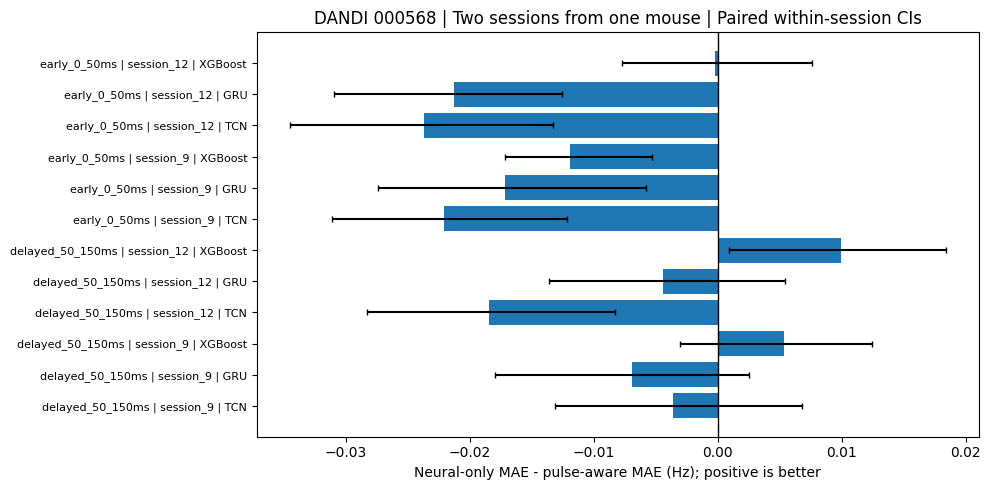

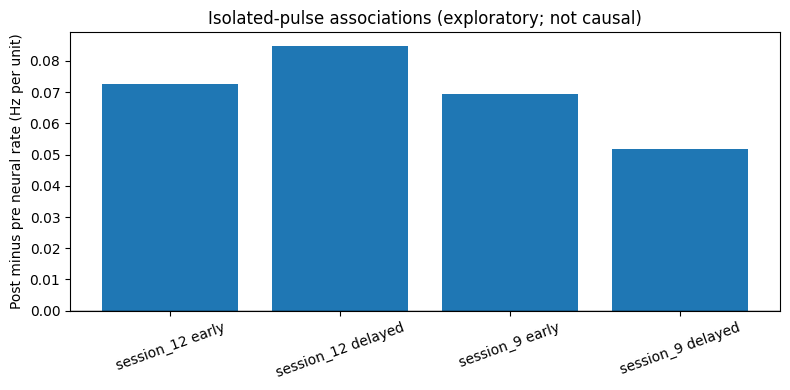

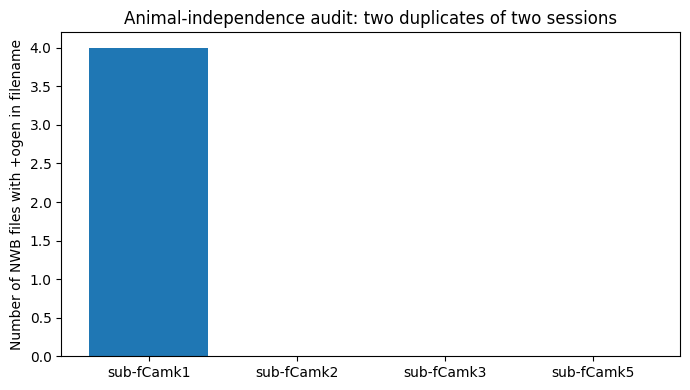

In [11]:
display_deltas=deltas.copy()
fig,ax=plt.subplots(figsize=(10,5))
labels=[];vals=[];errs=[]
for _,r in display_deltas.iterrows():
    if r['seed']!=REPEATS[0]:continue
    labels.append(f"{r['horizon']} | {r['test_session']} | {r['architecture']}")
    vals.append(r['delta_MAE_Hz'])
    errs.append((r['delta_MAE_Hz']-r['ci_low'],r['ci_high']-r['delta_MAE_Hz']))
ax.barh(np.arange(len(vals)),vals)
for i,(v,(lo,hi)) in enumerate(zip(vals,errs)):
    if np.isfinite(lo) and np.isfinite(hi):
        ax.errorbar(v,i,xerr=np.array([[max(lo,0)],[max(hi,0)]]),fmt='none',capsize=2,color='black')
ax.axvline(0,color='black',linewidth=1)
ax.set_yticks(np.arange(len(labels)),labels,fontsize=8)
ax.set_xlabel('Neural-only MAE - pulse-aware MAE (Hz); positive is better')
ax.set_title('DANDI 000568 | Two sessions from one mouse | Paired within-session CIs')
ax.invert_yaxis();fig.tight_layout()
fig.savefig(OUT/'fig_paired_optical_benefits_95CI.png',dpi=190)
plt.show();plt.close(fig)

fig,ax=plt.subplots(figsize=(8,4))
labels=[];centers=[]
for _,r in pulse_summary.iterrows():
    labels += [r['session']+' early',r['session']+' delayed']
    centers += [r['mean_early_delta'],r['mean_delayed_delta']]
if labels:
    ax.bar(labels,centers)
else:
    ax.text(.5,.5,'No qualifying isolated pulses',ha='center',va='center',transform=ax.transAxes)
ax.axhline(0,color='black',lw=1)
ax.set_ylabel('Post minus pre neural rate (Hz per unit)')
ax.set_title('Isolated-pulse associations (exploratory; not causal)')
ax.tick_params(axis='x',labelrotation=20)
fig.tight_layout();fig.savefig(OUT/'fig_isolated_pulse_early_vs_delayed.png',dpi=190)
plt.show();plt.close(fig)

fig,ax=plt.subplots(figsize=(7,4))
ax.bar(summary.subject,summary.marked_ogen_files)
ax.set_ylabel('Number of NWB files with +ogen in filename')
ax.set_title('Animal-independence audit: two duplicates of two sessions')
fig.tight_layout();fig.savefig(OUT/'fig_animal_ogen_filename_inventory.png',dpi=190)
plt.show();plt.close(fig)

In [12]:
meta={
 'dataset':'DANDI 000568','version':VERSION,'executed_utc':datetime.now(timezone.utc).isoformat(),
 'status':'real NWB conditional prediction benchmark','mode':'quick' if QUICK_MODE else 'full',
 'n_recording_sessions':len(SESSIONS),'n_independent_animals_with_verified_ogen':1,
 'bin_sec':BIN_SEC,'past_history_sec':HISTORY_BINS*BIN_SEC,
 'horizons_sec':{k:[v[0]*BIN_SEC,v[1]*BIN_SEC] for k,v in HORIZONS.items()},
 'observed_future_light_is_input':True,
 'codes_as_calibrated_intensity':False,
 'sampling':'balanced light-plan windows, separated endpoints; not prevalence representative',
 'split':'session held out, with training-session temporal validation embargo',
 'seeds':REPEATS,'epochs_max':EPOCHS,'train_caps':CAPS,
 'confidence_intervals':'within held-out session 60s block-bootstrap, NOT animal-level CI',
 'no_clinical_epilepsy_claim':True,'no_causal_intervention_claim':True,
 'limitations':[
  'Only one mouse has explicitly optogenetics-marked NWB sessions in this dataset manifest.',
  'Multiple windows/pulses from one mouse are biologically dependent.',
  'Raw optical codes 19 and >60000 are not calibrated as physical light power.',
  'Scheduled future light is an observed input, not a learned control action.',
  'Shuffling light inputs tests model reliance only, not causal treatment response.',
  'Pulse timing overlaps neural spike ranges but exact synchronization is not independently proven.',
  'This dataset is not human epilepsy data. No independent-animal generalization is demonstrated.']}
(OUT/'run_config_scientific_limitations.json').write_text(json.dumps(meta,indent=2))
(OUT/'README_for_paper.txt').write_text('PHASE 2C | Real mouse optogenetic neural-response study\n'
  'Start with paper_metrics_by_horizon_fold_and_group.csv and paired_optical_benefit_95CI.csv.\n'
  'Use heldout_predictions_both_horizons.csv to independently reproduce evaluation.\n'
  'Only mouse fCamk1 has explicit optogenetics-marked NWB sessions.\n'
  'The optical input is the OBSERVED future stimulation schedule, not a controllable treatment.\n'
  'Raw optical codes are UNCALIBRATED, so no watts/dose-response conclusions.\n'
  'Pulse-locked pre/post comparisons are observational, non-causal and not independent-animal evidence.\n'
  'Full manuscript results require additional subjects and repeated random seeds.\n')
zip_path=ROOT/'phase2c_pulseaware_validation_results.zip'
with zipfile.ZipFile(zip_path,'w',compression=zipfile.ZIP_DEFLATED,compresslevel=6) as zz:
    for p in OUT.iterdir():
        if p.is_file():zz.write(p,arcname=p.name)
print('\nCOMPLETED:',zip_path,'size MB:',round(zip_path.stat().st_size/1e6,2))
print('Upload this ZIP in our research chat for next-stage analysis.')


COMPLETED: /kaggle/working/phase2c_pulseaware_validation_results.zip size MB: 1.58
Upload this ZIP in our research chat for next-stage analysis.
